In [1]:
import glob
from Autoencoder.latent_check.latent_dih_analysis import *
import torch, torch.nn as nn

In [9]:
checkpoint = ("../../results_real/AE_dihedral_261026/dihedral_ae_n_v1/all_runs_streamed/models/ae_latent128.pt")
dev = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [3]:
GROUP = "seq"

In [4]:
class AE(nn.Module):
    def __init__(self, n_in, latent, HIDDEN):
        super().__init__()
        h1, h2 = HIDDEN
        self.enc = nn.Sequential(nn.Linear(n_in, h1), nn.GELU(), nn.Linear(h1, h2), nn.GELU(),
                                 nn.Linear(h2, latent))
        self.dec = nn.Sequential(nn.Linear(latent, h2), nn.GELU(), nn.Linear(h2, h1), nn.GELU(),
                                 nn.Linear(h1, n_in), nn.Tanh())

    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z

In [3]:
def load_model(cpkt, device='cpu'):
    ck=torch.load(cpkt, map_location=device, weights_only=False)
    model = AE(ck['n_in'], ck['latent'], HIDDEN=tuple(ck['hidden']))
    model.load_state_dict(ck['state_dict'])
    model.eval().to(device)
    return model, list(ck['all_names']), ck
def prepare_input(deg, names, all_names):
    pos = {n: i for i, n in enumerate(all_names)}
    keep = [j for j, n in enumerate(names) if n in pos]
    unknown = [n for n in names if n not in pos]
    if unknown:
        warnings.warn(f"{len(unknown)} column(s) are not known to the model and are dropped: {unknown[:8]}")
    if not keep:
        raise ValueError("none of the columns match the model's all_names")
    idx = [pos[names[j]] for j in keep]
    D = len(all_names)
    full = np.zeros((len(deg), D), np.float32)
    full[:, idx] = np.asarray(deg, np.float32)[:, keep]
    pres = np.zeros(D, bool)
    pres[idx] = True
    m = pres.astype(np.float32)
    r = np.deg2rad(full).astype(np.float32)
    x = np.concatenate([np.cos(r) * m, np.sin(r) * m], axis=1).astype(np.float32)
    x = np.nan_to_num(x, nan=0.0).astype(np.float32)
    mask = np.concatenate([m, m])
    return x, mask, full, pres

In [10]:
model, all_names, ck = load_model(checkpoint, dev)
files = sorted(glob.glob("../../dihedrals/*/bb_dihedrals.txt"))
data = collect_latents(model, all_names, files, prepare_input, stride=50, max_per_run=1000, device=dev)
add_labels(data)
describe_labels(data)
z = data["z"]; p = pca(z)

seq: 112 (1 runs, 163 frames), 113 (1 runs, 212 frames), 141 (1 runs, 913 frames), 144 (1 runs, 1,000 frames), 222 (1 runs, 706 frames), 323 (1 runs, 1,000 frames), 324 (2 runs, 1,637 frames), 333 (1 runs, 1,000 frames), 342 (1 runs, 206 frames), 344 (1 runs, 1,000 frames), 411 (1 runs, 135 frames), 432 (1 runs, 1,000 frames), 443 (1 runs, 659 frames), 444 (2 runs, 2,000 frames)
top: +l+l+l (1 runs, 659 frames), +p+l+l (1 runs, 206 frames), +p+l+p (2 runs, 1,163 frames), +p+p+p (1 runs, 1,000 frames), -l-l-l (1 runs, 135 frames), -l-l-p (1 runs, 706 frames), -l-p-p (1 runs, 1,000 frames), -ld+p (1 runs, 212 frames), -p-l-p (1 runs, 913 frames), -p-p-l (3 runs, 3,000 frames), -p-p-p (1 runs, 720 frames), d+pd (2 runs, 1,917 frames)
lay: aa (6 runs, 3,964 frames), as (3 runs, 2,659 frames), sa (5 runs, 3,932 frames), ss (2 runs, 1,076 frames)
copy: 1 (7 runs, 5,006 frames), 2 (3 runs, 2,365 frames), 3 (6 runs, 4,260 frames)


latent size 128: 128 dimensions with std > 1% of the largest one
PCA: 30 components for 90% of the variance, 65 for 99%; participation ratio 16.0


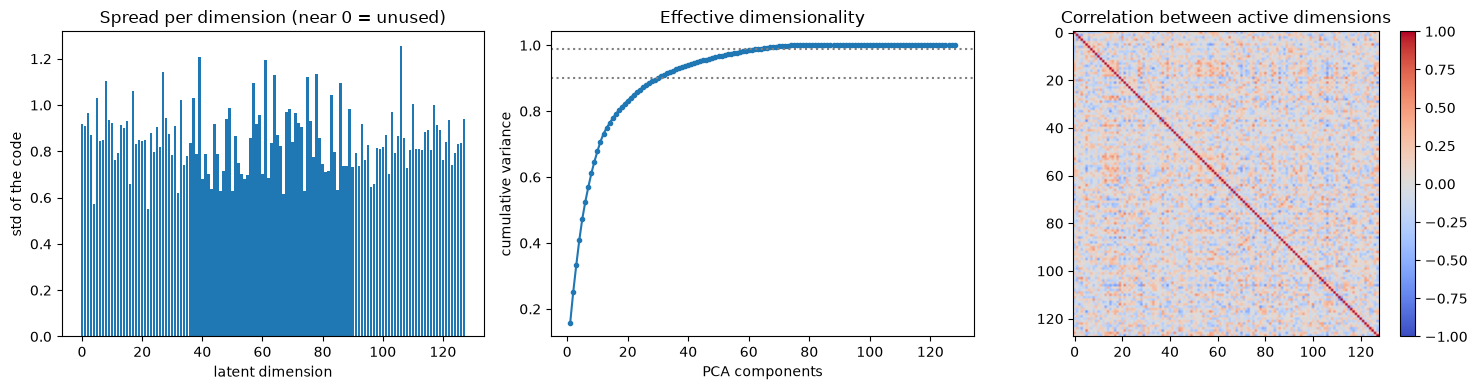

In [11]:
plot_overview(z, p)                                       # 1

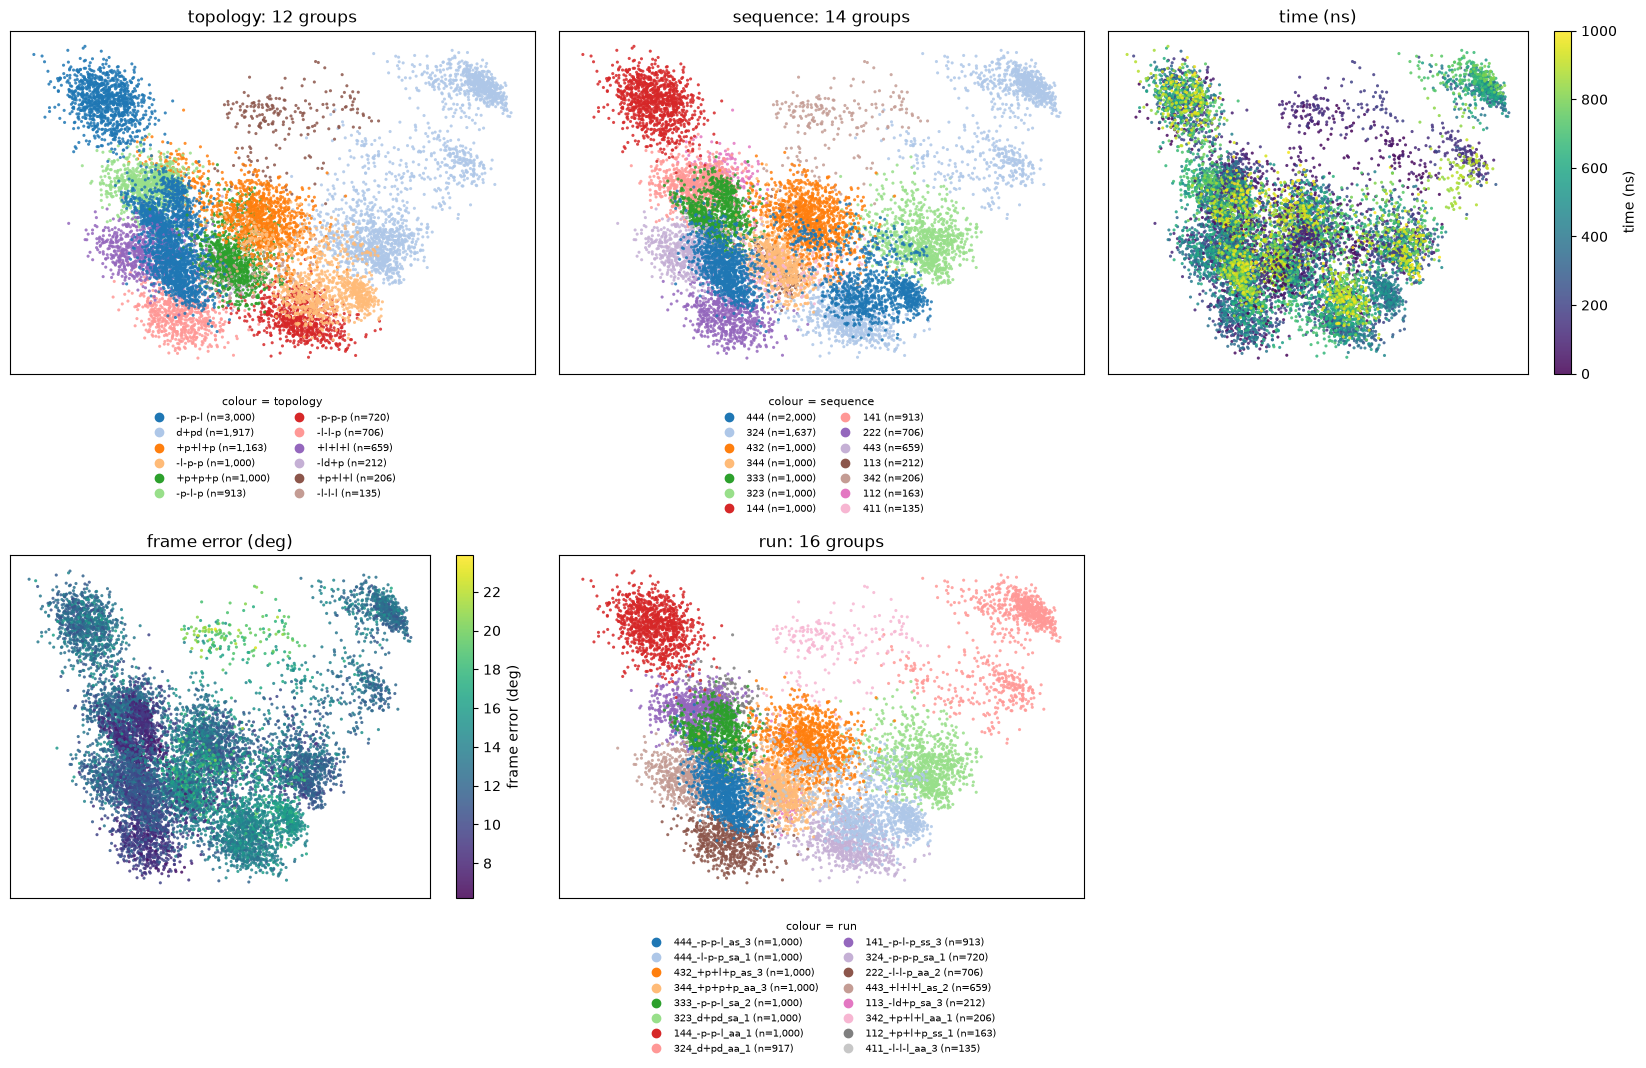

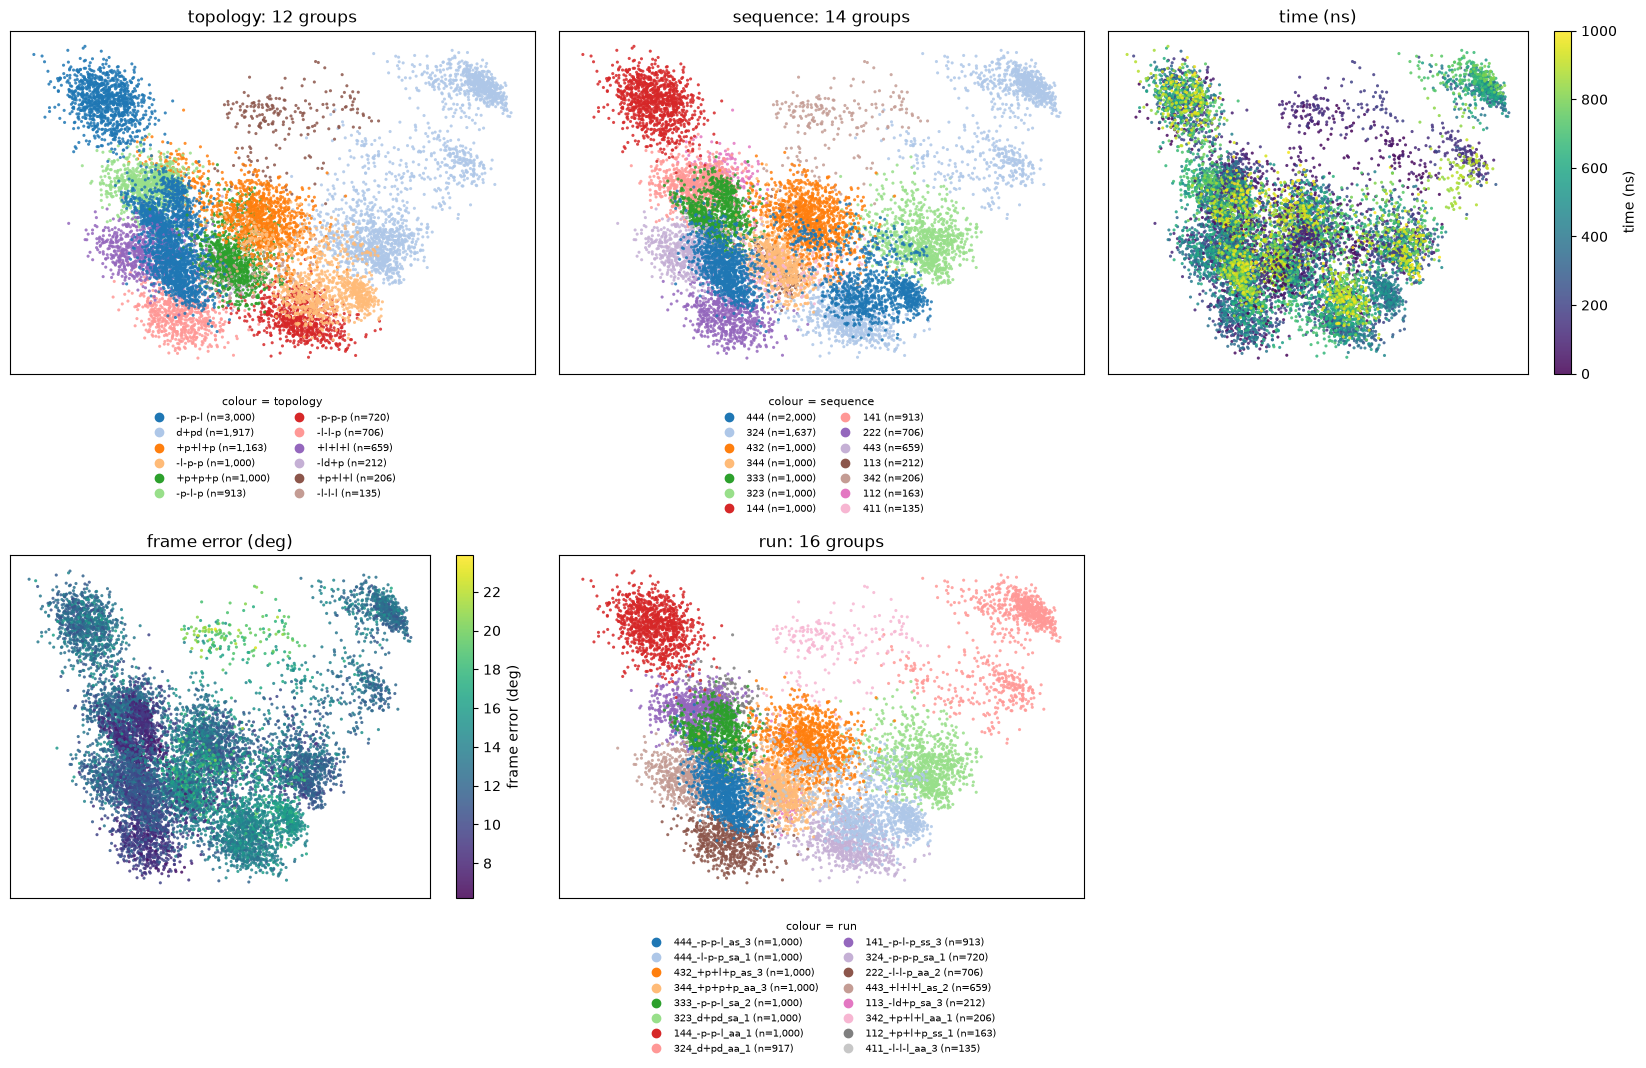

In [12]:
xy, sel = embed_2d(z, "pca")                              # "pca", "tsne" (scikit-learn) or "umap"
scatter_maps(xy, default_panels(data, sel, keys=("top", "seq", "t_ns", "err", "run")), show=False)   # 2

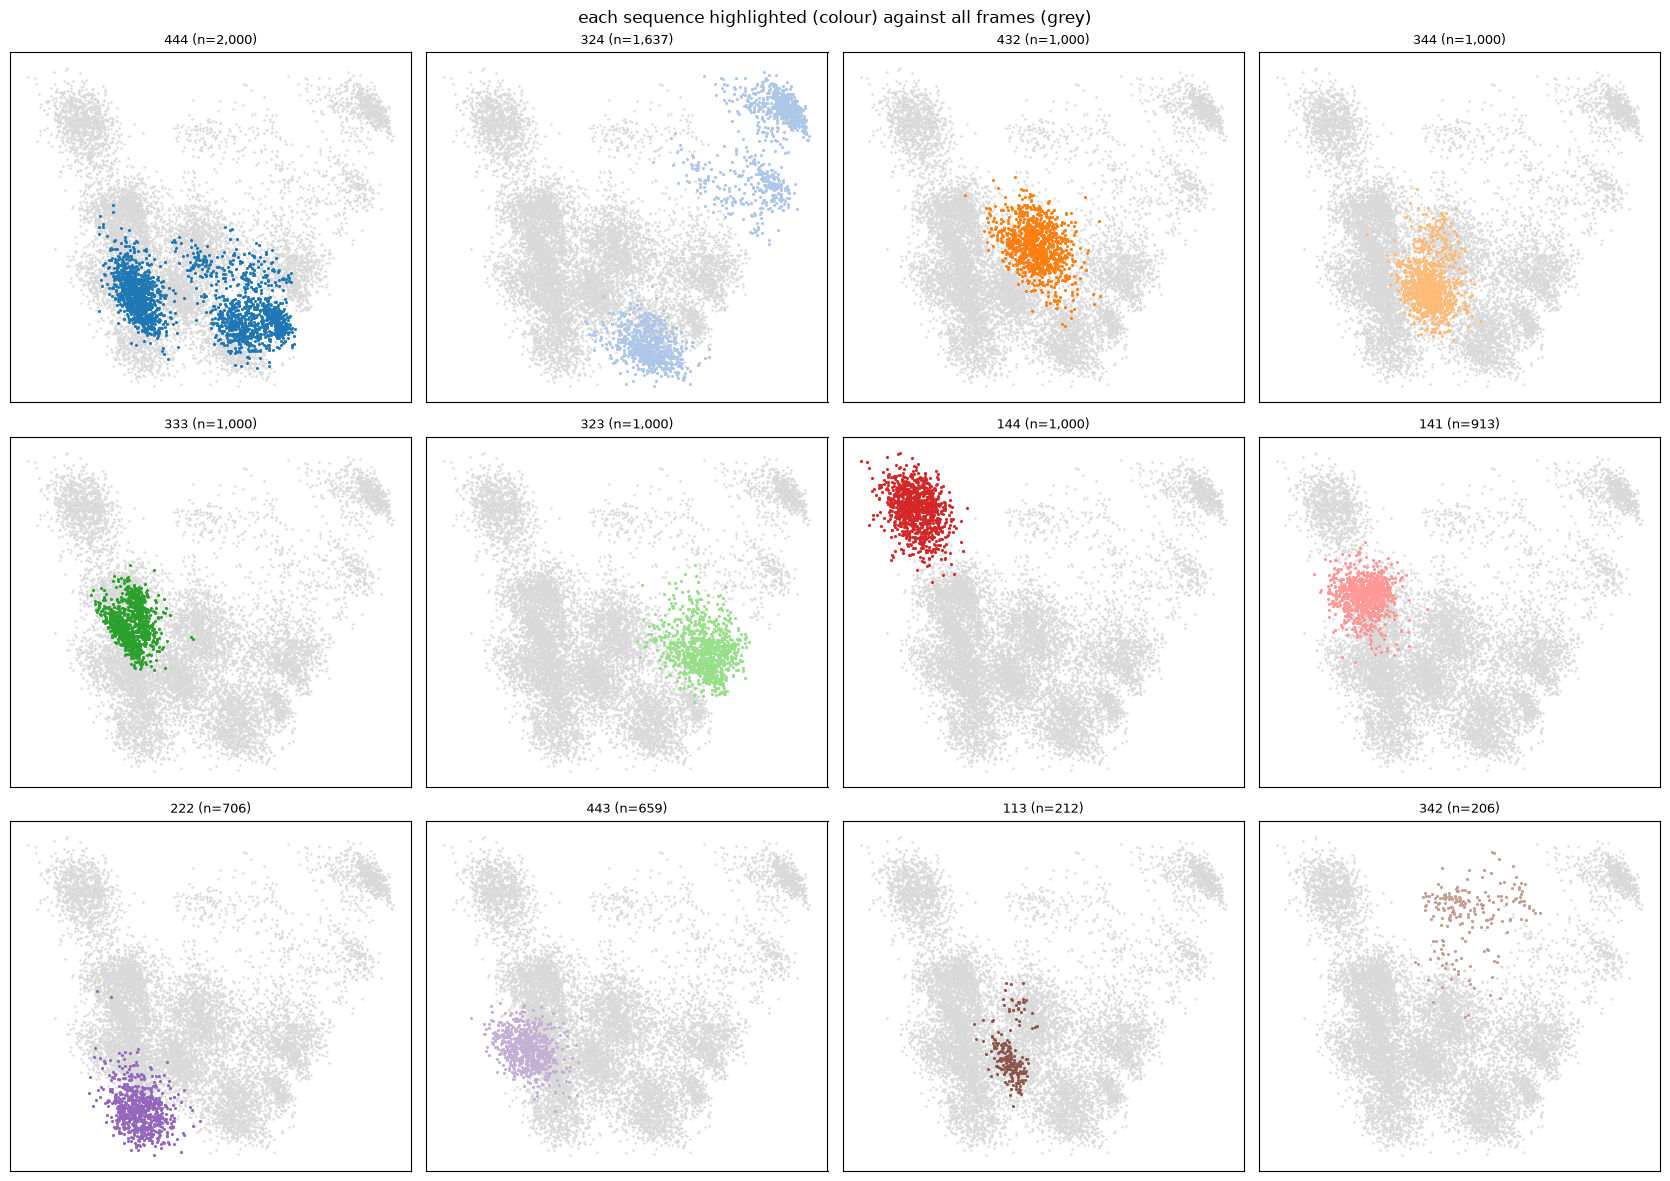

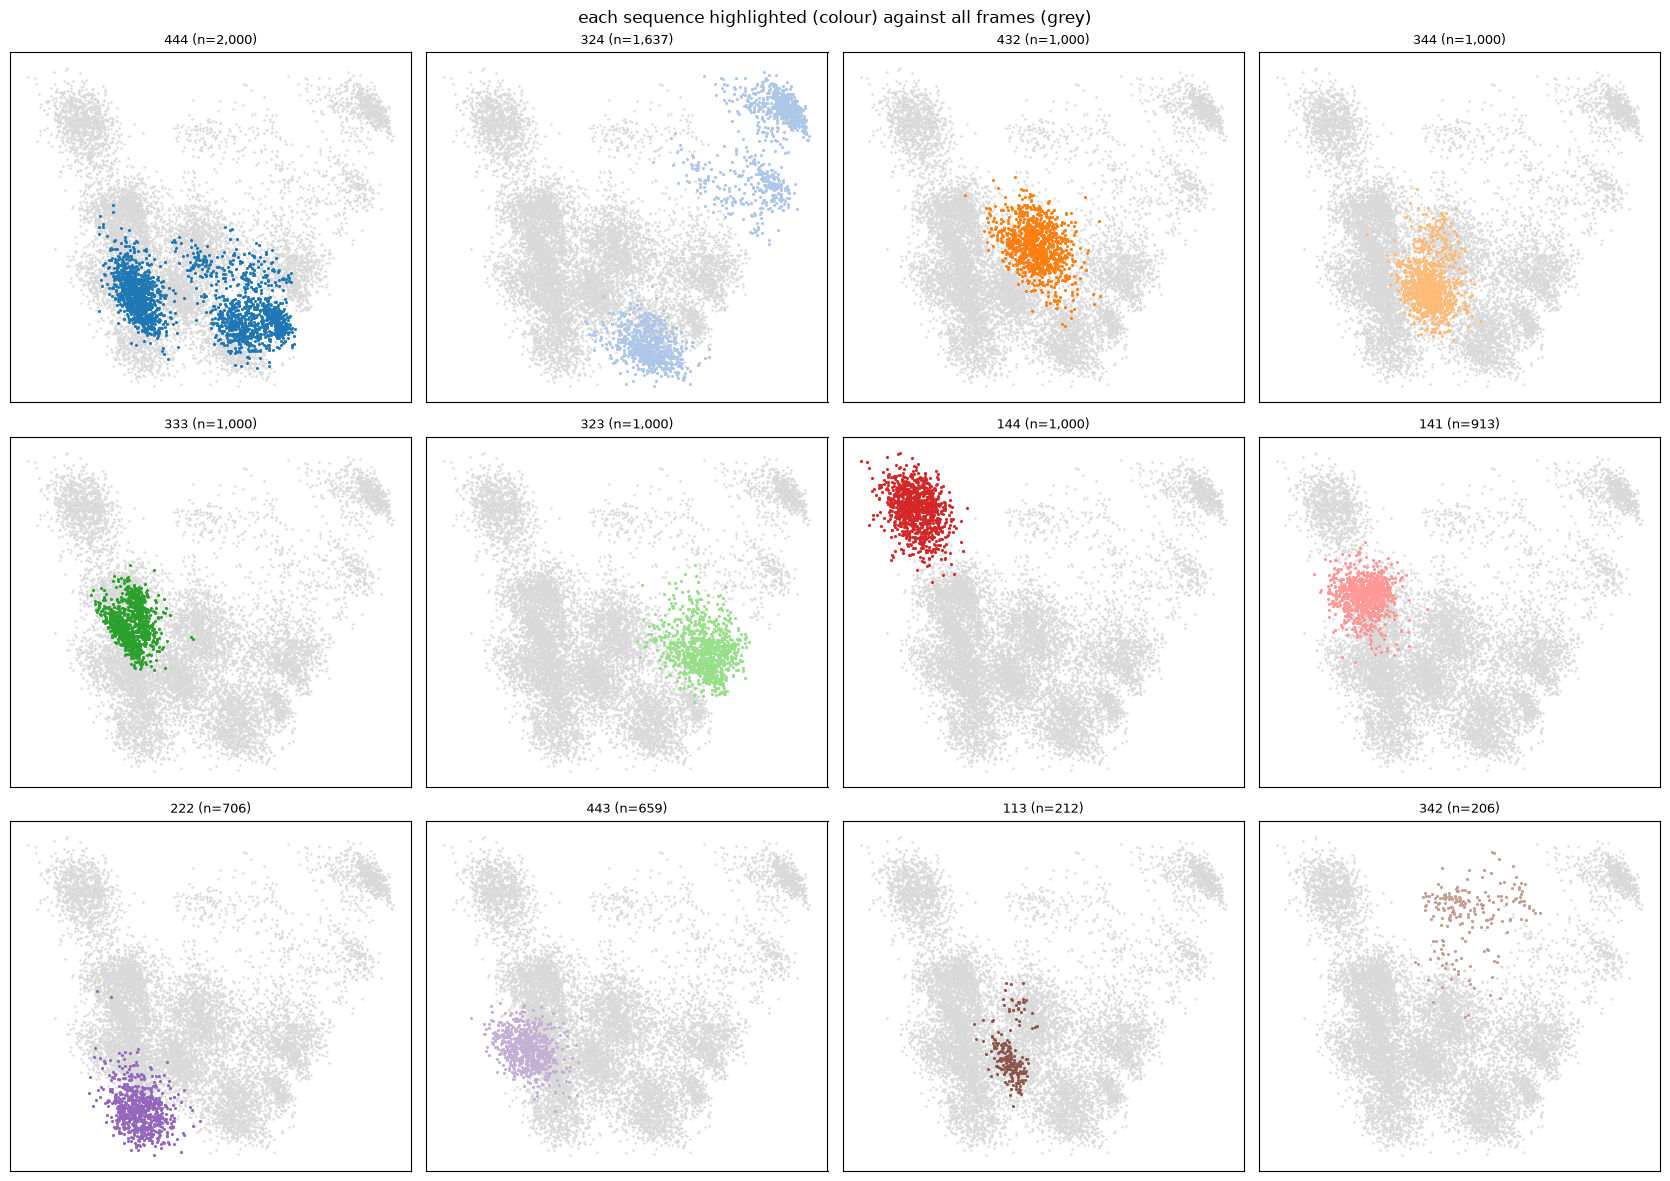

In [13]:
highlight_groups(xy, data["seq"][sel], title="sequence")

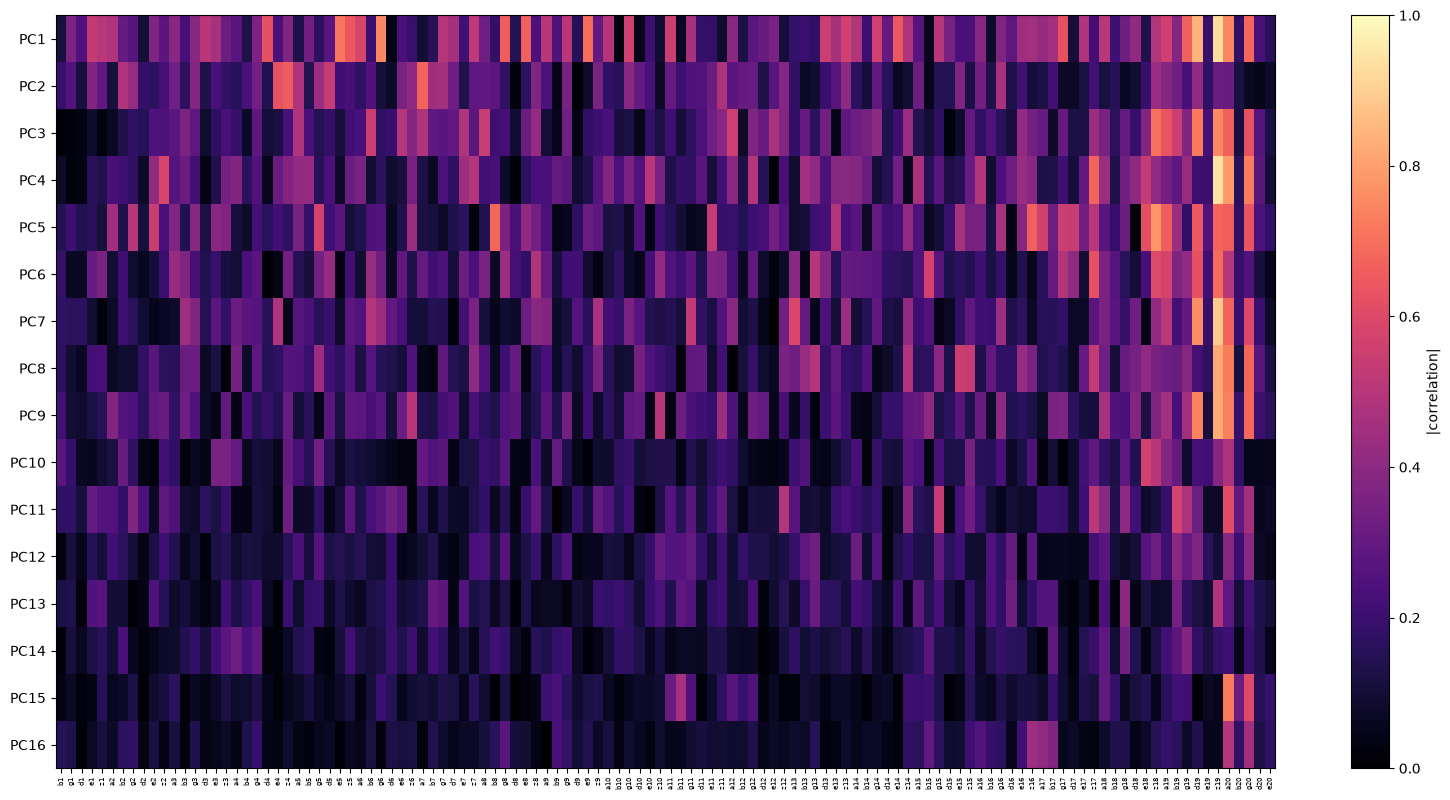

PC1: z19 (0.93), d19 (0.84), g6 (0.75)
PC2: a7 (0.67), z4 (0.66), e4 (0.63)
PC3: z19 (0.75), d19 (0.72), z18 (0.70)
PC4: z19 (0.94), a20 (0.79), g20 (0.73)
PC5: z18 (0.78), b8 (0.68), z19 (0.68)


array([[0.11547245, 0.36168706, 0.24851349, ..., 0.68343347, 0.2333404 ,
        0.15865096],
       [0.19729042, 0.2590422 , 0.11456449, ..., 0.0687592 , 0.04827541,
        0.08062375],
       [0.02254555, 0.02242705, 0.03337857, ..., 0.62889743, 0.26340103,
        0.12431503],
       ...,
       [0.01493973, 0.11466359, 0.06160861, ..., 0.19748341, 0.13885562,
        0.04689585],
       [0.03869031, 0.06842653, 0.02052669, ..., 0.59900385, 0.15599021,
        0.19441353],
       [0.15610512, 0.13695399, 0.01723935, ..., 0.4520205 , 0.12582961,
        0.17699866]])

In [25]:
latent_dihedral_corr(p["scores"], data["true"], data["valid"], all_names, n_dims=16)                # 3

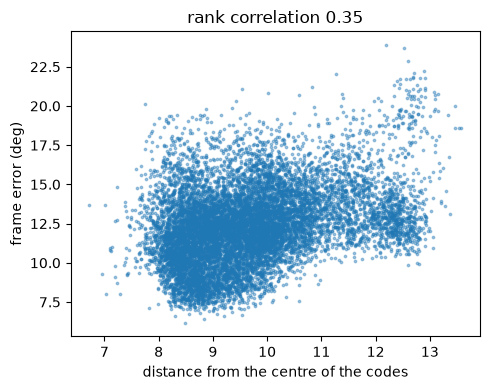

0.3494426578817916

In [24]:
error_vs_distance(z, data["err"])